# Лабораторна робота 8. Перенесення навчання (Transfer Learning): VGG16

## Завантаження набору даних з Google Диска

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import glob, shutil

# шукаємо архів dogs-vs-cats.zip з Kaggle у будь-якій папці Google Диска
found = glob.glob('/content/drive/MyDrive/**/dogs-vs-cats*.zip', recursive=True)
print(found)
assert found, 'Архів dogs-vs-cats.zip не знайдено на Google Диску'
shutil.copy(found[0], '/content/dogs-vs-cats.zip')

['/content/drive/MyDrive/dogs-vs-cats.zip']


'/content/dogs-vs-cats.zip'

In [3]:
# розпаковуємо архів з Kaggle, а потім train.zip з 25 000 зображень
!unzip -q -o /content/dogs-vs-cats.zip -d /content/dogs-vs-cats
!unzip -q -o /content/dogs-vs-cats/train.zip -d /content/dogs-vs-cats
!ls /content/dogs-vs-cats/train | wc -l

25000


## Підготовка набору даних (скрипт prepare_dataset.py з лабораторної роботи 7)

In [4]:
%%writefile prepare_dataset.py
"""Підготовка набору даних Dogs vs. Cats для навчання нейронної мережі в Keras.

Зображення з каталогу data_dir (25 000 файлів cat.N.jpg і dog.N.jpg з Kaggle) розподіляються
на три набори: для навчання (70%), перевірки (15%) і тестування (15%).
У кожному наборі створюються підкаталоги cats і dogs, як потрібно для flow_from_directory.
"""
import os
import shutil

# Каталог з набором даних (розпакований train.zip з Kaggle)
data_dir = '/content/dogs-vs-cats/train'
# Каталог з даними для навчання
train_dir = 'train'
# Каталог з даними для перевірки
val_dir = 'val'
# Каталог з даними для тестування
test_dir = 'test'
# Частина набору даних для тестування
test_data_portion = 0.15
# Частина набору даних для перевірки
val_data_portion = 0.15
# Кількість зображень в одному класі
nb_images = 12500


def create_directory(dir_name):
    """Створює каталог dir_name з підкаталогами cats і dogs (старий каталог видаляється)."""
    if os.path.exists(dir_name):
        shutil.rmtree(dir_name)
    os.makedirs(dir_name)
    os.makedirs(os.path.join(dir_name, "cats"))
    os.makedirs(os.path.join(dir_name, "dogs"))


def copy_images(start_index, end_index, source_dir, dest_dir):
    """Копіює зображення котів і собак з номерами від start_index до end_index у підкаталоги cats і dogs."""
    for i in range(start_index, end_index):
        shutil.copy2(os.path.join(source_dir, "cat." + str(i) + ".jpg"),
                     os.path.join(dest_dir, "cats"))
        shutil.copy2(os.path.join(source_dir, "dog." + str(i) + ".jpg"),
                     os.path.join(dest_dir, "dogs"))


create_directory(train_dir)
create_directory(val_dir)
create_directory(test_dir)

# Індекси, з яких починаються набори для перевірки і тестування
start_val_data_idx = int(nb_images * (1 - val_data_portion - test_data_portion))
start_test_data_idx = int(nb_images * (1 - test_data_portion))
print(start_val_data_idx)
print(start_test_data_idx)

copy_images(0, start_val_data_idx, data_dir, train_dir)
copy_images(start_val_data_idx, start_test_data_idx, data_dir, val_dir)
copy_images(start_test_data_idx, nb_images, data_dir, test_dir)

for d in (train_dir, val_dir, test_dir):
    print(d, ': cats -', len(os.listdir(os.path.join(d, "cats"))), ', dogs -', len(os.listdir(os.path.join(d, "dogs"))))

Writing prepare_dataset.py


In [5]:
!python prepare_dataset.py

8750
10625
train : cats - 8750 , dogs - 8750
val : cats - 1875 , dogs - 1875
test : cats - 1875 , dogs - 1875


## Підключаємо бібліотеки

In [6]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import load_img, img_to_array

## Константи

In [7]:
# Каталог з даними для навчання
train_dir = 'train'
# Каталог з даними для перевірки
val_dir = 'val'
# Каталог з даними для тестування
test_dir = 'test'
# Розміри зображення
img_width, img_height = 150, 150
# Розмірність тензору на основі зображення для вхідних даних в нейронну мережу
input_shape = (img_width, img_height, 3)
# Кількість епох
epochs = 10
# Розмір міні-вибірки
batch_size = 16

## Генератори зображень

In [8]:
# як у лекції: значення пікселів діляться на 255
datagen = ImageDataGenerator(rescale=1. / 255)

train_generator = datagen.flow_from_directory(
    train_dir,
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode='binary')

val_generator = datagen.flow_from_directory(
    val_dir,
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode='binary')

test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode='binary')

print(train_generator.class_indices)

Found 17500 images belonging to 2 classes.
Found 3750 images belonging to 2 classes.
Found 3750 images belonging to 2 classes.
{'cats': 0, 'dogs': 1}


## Завантажуємо попередньо навчену мережу VGG16 без частини для класифікації

In [9]:
vgg16_net = VGG16(weights='imagenet',
                  include_top=False,
                  input_shape=input_shape)
# згорткову частину не навчаємо
vgg16_net.trainable = False
vgg16_net.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

## Складена мережа

In [10]:
def create_model(dropout_rate):
    """Складена мережа: заморожена згорткова частина + новий класифікатор для двох класів."""
    model = Sequential()
    model.add(Input(shape=input_shape))
    # Додаємо мережу vgg16_net в модель як шар
    model.add(vgg16_net)
    model.add(Flatten())
    model.add(Dense(256, activation='relu'))
    if dropout_rate > 0:
        model.add(Dropout(dropout_rate))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(loss='binary_crossentropy',
                  optimizer=Adam(learning_rate=1e-5),
                  metrics=['accuracy'])
    return model

In [11]:
def plot_history(history, title):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='навчальна')
    plt.plot(epochs_range, val_acc, label='перевірочна')
    plt.title(title + ': точність'); plt.xlabel('Епоха'); plt.legend(); plt.grid()
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='навчальна')
    plt.plot(epochs_range, val_loss, label='перевірочна')
    plt.title(title + ': помилка (loss)'); plt.xlabel('Епоха'); plt.legend(); plt.grid()
    plt.show()

## Навчання з Dropout 0.5

In [12]:
model_d05 = create_model(0.5)
model_d05.summary()

history_model_d05 = model_d05.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=epochs,
    validation_data=val_generator,
    validation_steps=len(val_generator))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 65s 54ms/step - accuracy: 0.7979 - loss: 0.4273 - val_accuracy: 0.8851 - val_loss: 0.2940
Epoch 2/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 73s 50ms/step - accuracy: 0.8757 - loss: 0.2924 - val_accuracy: 0.8989 - val_loss: 0.2568
Epoch 3/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 53s 48ms/step - accuracy: 0.8935 - loss: 0.2573 - val_accuracy: 0.9013 - val_loss: 0.2412
Epoch 4/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 52s 48ms/step - accuracy: 0.8975 - loss: 0.2409 - val_accuracy: 0.9080 - val_loss: 0.2317
Epoch 5/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 53s 49ms/step - accuracy: 0.9031 - loss: 0.2271 - val_accuracy: 0.9096 - val_loss: 0.2244
Epoch 6/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 52s 48ms/step - accuracy: 0.9132 - loss: 0.2129 - val_accuracy: 0.9104 - val_loss: 0.2222
Epoch 7/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 52s 47ms/step - accuracy: 0.9167 - loss: 0.2044 - val_accuracy: 0.9112 - val_loss: 0.2156
Epoch 8/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 54s 49ms/step - accuracy: 0.9181 -

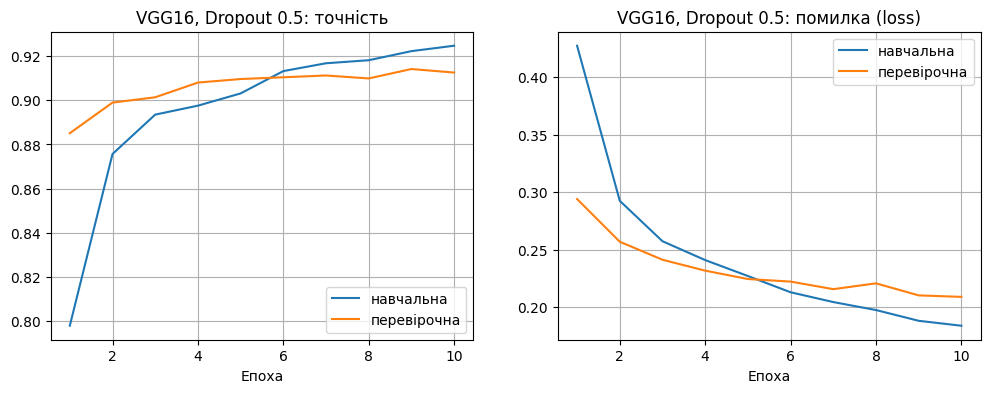

In [13]:
plot_history(history_model_d05, 'VGG16, Dropout 0.5')

In [14]:
scores_model_d05 = model_d05.evaluate(test_generator, steps=len(test_generator))
print("Точність на тестових даних (VGG16, Dropout 0.5): %.2f%%" % (scores_model_d05[1] * 100))

235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms/step - accuracy: 0.9147 - loss: 0.2129
Точність на тестових даних (VGG16, Dropout 0.5): 91.47%


## Навчання з Dropout 0.3

In [15]:
model_d03 = create_model(0.3)
model_d03.summary()

history_model_d03 = model_d03.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=epochs,
    validation_data=val_generator,
    validation_steps=len(val_generator))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 58s 50ms/step - accuracy: 0.8202 - loss: 0.3916 - val_accuracy: 0.8800 - val_loss: 0.2845
Epoch 2/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 53s 49ms/step - accuracy: 0.8850 - loss: 0.2710 - val_accuracy: 0.8997 - val_loss: 0.2484
Epoch 3/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 52s 47ms/step - accuracy: 0.9010 - loss: 0.2394 - val_accuracy: 0.9037 - val_loss: 0.2330
Epoch 4/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 52s 48ms/step - accuracy: 0.9087 - loss: 0.2216 - val_accuracy: 0.9083 - val_loss: 0.2260
Epoch 5/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 55s 50ms/step - accuracy: 0.9161 - loss: 0.2073 - val_accuracy: 0.9109 - val_loss: 0.2198
Epoch 6/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 79s 47ms/step - accuracy: 0.9180 - loss: 0.1998 - val_accuracy: 0.9115 - val_loss: 0.2164
Epoch 7/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 53s 48ms/step - accuracy: 0.9234 - loss: 0.1875 - val_accuracy: 0.9120 - val_loss: 0.2155
Epoch 8/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 51s 47ms/step - accuracy: 0.9266 -

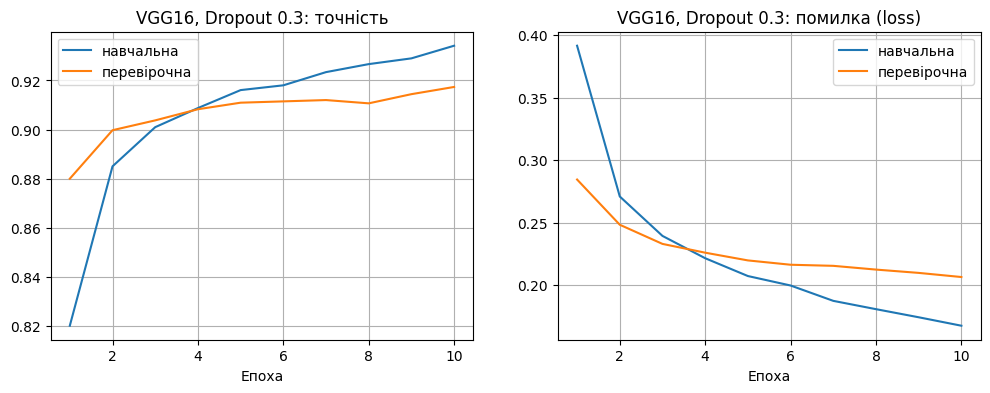

In [16]:
plot_history(history_model_d03, 'VGG16, Dropout 0.3')

In [17]:
scores_model_d03 = model_d03.evaluate(test_generator, steps=len(test_generator))
print("Точність на тестових даних (VGG16, Dropout 0.3): %.2f%%" % (scores_model_d03[1] * 100))

235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - accuracy: 0.9147 - loss: 0.2070
Точність на тестових даних (VGG16, Dropout 0.3): 91.47%


## Навчання без Dropout

In [18]:
model_d0 = create_model(0.0)
model_d0.summary()

history_model_d0 = model_d0.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=epochs,
    validation_data=val_generator,
    validation_steps=len(val_generator))

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 56s 49ms/step - accuracy: 0.8469 - loss: 0.3608 - val_accuracy: 0.8909 - val_loss: 0.2756
Epoch 2/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 78s 46ms/step - accuracy: 0.8981 - loss: 0.2484 - val_accuracy: 0.9056 - val_loss: 0.2434
Epoch 3/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 51s 47ms/step - accuracy: 0.9106 - loss: 0.2201 - val_accuracy: 0.9077 - val_loss: 0.2283
Epoch 4/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 51s 46ms/step - accuracy: 0.9174 - loss: 0.2042 - val_accuracy: 0.9133 - val_loss: 0.2214
Epoch 5/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 51s 47ms/step - accuracy: 0.9222 - loss: 0.1909 - val_accuracy: 0.9155 - val_loss: 0.2152
Epoch 6/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 53s 49ms/step - accuracy: 0.9278 - loss: 0.1819 - val_accuracy: 0.9149 - val_loss: 0.2106
Epoch 7/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 51s 47ms/step - accuracy: 0.9325 - loss: 0.1728 - val_accuracy: 0.9171 - val_loss: 0.2098
Epoch 8/10
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 52s 47ms/step - accuracy: 0.9357 -

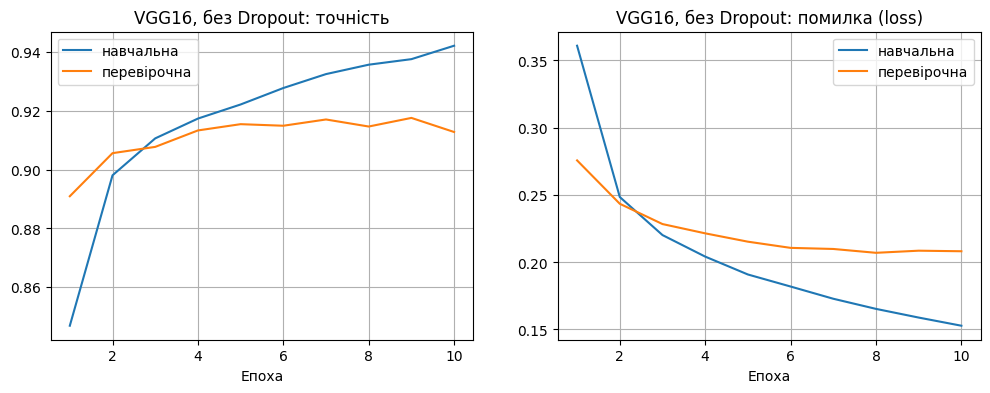

In [19]:
plot_history(history_model_d0, 'VGG16, без Dropout')

In [20]:
scores_model_d0 = model_d0.evaluate(test_generator, steps=len(test_generator))
print("Точність на тестових даних (VGG16, без Dropout): %.2f%%" % (scores_model_d0[1] * 100))

235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - accuracy: 0.9125 - loss: 0.2131
Точність на тестових даних (VGG16, без Dropout): 91.25%


## Вплив Dropout на перенавчання

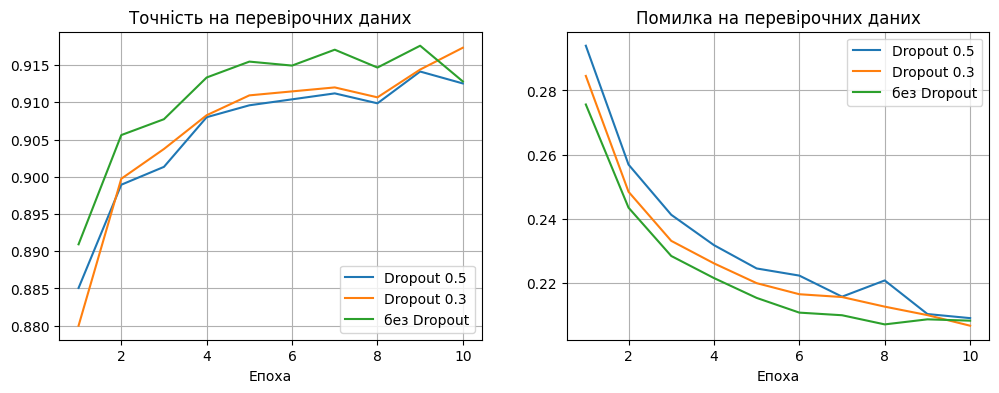

Dropout 0.5 : навчальна 92.47%, перевірочна 91.25%, тестова 91.47%, різниця навч.-перевір. 1.22%
Dropout 0.3 : навчальна 93.41%, перевірочна 91.73%, тестова 91.47%, різниця навч.-перевір. 1.68%
без Dropout : навчальна 94.22%, перевірочна 91.28%, тестова 91.25%, різниця навч.-перевір. 2.94%


In [21]:
results = {'Dropout 0.5': (history_model_d05, scores_model_d05),
           'Dropout 0.3': (history_model_d03, scores_model_d03),
           'без Dropout': (history_model_d0, scores_model_d0)}

plt.figure(figsize=(12, 4))
for k, (name, (h, s)) in enumerate(results.items()):
    plt.subplot(1, 2, 1); plt.plot(range(1, epochs + 1), h.history['val_accuracy'], label=name)
    plt.subplot(1, 2, 2); plt.plot(range(1, epochs + 1), h.history['val_loss'], label=name)
plt.subplot(1, 2, 1); plt.title('Точність на перевірочних даних'); plt.xlabel('Епоха'); plt.legend(); plt.grid()
plt.subplot(1, 2, 2); plt.title('Помилка на перевірочних даних'); plt.xlabel('Епоха'); plt.legend(); plt.grid()
plt.show()

for name, (h, s) in results.items():
    print(f"{name:12s}: навчальна {h.history['accuracy'][-1]*100:.2f}%, перевірочна {h.history['val_accuracy'][-1]*100:.2f}%, "
          f"тестова {s[1]*100:.2f}%, різниця навч.-перевір. {(h.history['accuracy'][-1] - h.history['val_accuracy'][-1])*100:.2f}%")

## Збереження моделей на Google Диск

In [22]:
save_dir = '/content/drive/MyDrive/Lab8_models'
os.makedirs(save_dir, exist_ok=True)
model_d05.save(os.path.join(save_dir, 'vgg16_dropout05.h5'), include_optimizer=False)
model_d03.save(os.path.join(save_dir, 'vgg16_dropout03.h5'), include_optimizer=False)
model_d0.save(os.path.join(save_dir, 'vgg16_no_dropout.h5'), include_optimizer=False)
!ls -lh {save_dir}

# для розпізнавання беремо модель з найвищою точністю на тестових даних
best_name, (best_model, best_scores) = max([('Dropout 0.5', (model_d05, scores_model_d05)),
                                            ('Dropout 0.3', (model_d03, scores_model_d03)),
                                            ('без Dropout', (model_d0, scores_model_d0))], key=lambda t: t[1][1][1])
print('Найкраща модель VGG16:', best_name, '%.2f%%' % (best_scores[1] * 100))

total 295M
-rw------- 1 root root 102M Oct 23 21:25 inceptionv3_dropout05.h5
-rw------- 1 root root  65M Oct 25 12:48 vgg16_dropout03.h5
-rw------- 1 root root  65M Oct 25 12:48 vgg16_dropout05.h5
-rw------- 1 root root  65M Oct 25 12:48 vgg16_no_dropout.h5
Найкраща модель VGG16: Dropout 0.5 91.47%


## Розпізнавання власних зображень (ті самі, що в лабораторній роботі 7)

In [23]:
# копіюємо зображення з папки images_cats_dogs на Google Диску в робочий каталог
img_dirs = glob.glob('/content/drive/MyDrive/**/images_cats_dogs', recursive=True)
print(img_dirs)
assert img_dirs, 'Папку images_cats_dogs не знайдено на Google Диску'
for f in glob.glob(os.path.join(img_dirs[0], '*.jpg')):
    shutil.copy(f, '/content/')
print(len(glob.glob('/content/*.jpg')), 'зображень')

['/content/drive/MyDrive/Deep learning/images_cats_dogs']
47 зображень


In [24]:
def prepare(x):
    """Обробка зображення для VGG16, як у генераторі."""
    return x / 255.


def recognize(pattern, title):
    """Розпізнає всі зображення, що відповідають шаблону pattern, і показує їх з відповіддю мережі.
    Правильна відповідь береться з назви файлу: cat_... або dog_... (hard_cat_..., crop_dog_... тощо)."""
    names = sorted(glob.glob(pattern))
    cols = 5
    rows = (len(names) + cols - 1) // cols
    plt.figure(figsize=(3 * cols, 3.4 * rows), dpi=60)
    correct = 0
    for i, fn in enumerate(names):
        img = load_img(fn, target_size=(img_width, img_height))
        x = prepare(img_to_array(img))                          # така сама обробка, як у генераторі
        x = np.expand_dims(x, axis=0)
        p = float(best_model.predict(x, verbose=0)[0][0])     # ймовірність класу dogs
        pred = 'dog' if p > 0.5 else 'cat'
        true = 'dog' if 'dog' in os.path.basename(fn) else 'cat'
        correct += pred == true
        conf = p if pred == 'dog' else 1 - p
        print(f"{os.path.basename(fn)}: правильно - {true}, мережа - {pred} ({conf*100:.1f}%) {'✓' if pred == true else '✗'}")
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(f"{os.path.basename(fn)}\n{pred} ({conf*100:.1f}%)", color='green' if pred == true else 'red')
        plt.axis('off')
    plt.suptitle(title)
    plt.show()
    print(f"Правильно розпізнано: {correct} з {len(names)}")

### 10 котів і 10 собак

cat_01.jpg: правильно - cat, мережа - cat (93.8%) ✓
cat_02.jpg: правильно - cat, мережа - cat (99.8%) ✓
cat_03.jpg: правильно - cat, мережа - dog (63.3%) ✗
cat_04.jpg: правильно - cat, мережа - cat (99.9%) ✓
cat_05.jpg: правильно - cat, мережа - cat (78.5%) ✓
cat_06.jpg: правильно - cat, мережа - cat (85.1%) ✓
cat_07.jpg: правильно - cat, мережа - dog (51.0%) ✗
cat_08.jpg: правильно - cat, мережа - dog (90.6%) ✗
cat_09.jpg: правильно - cat, мережа - cat (71.2%) ✓
cat_10.jpg: правильно - cat, мережа - cat (88.3%) ✓


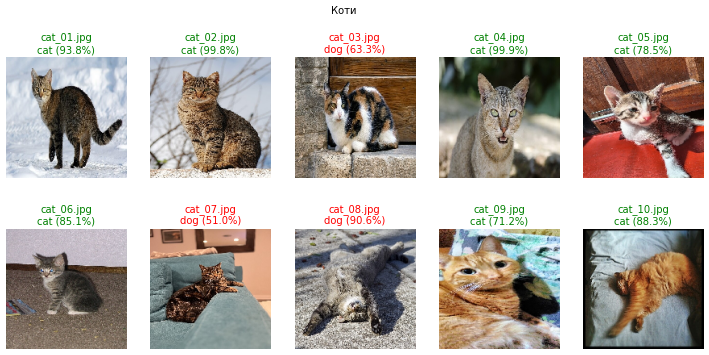

Правильно розпізнано: 7 з 10
dog_01.jpg: правильно - dog, мережа - dog (98.7%) ✓
dog_02.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_03.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_04.jpg: правильно - dog, мережа - dog (99.6%) ✓
dog_05.jpg: правильно - dog, мережа - dog (81.4%) ✓
dog_06.jpg: правильно - dog, мережа - dog (97.6%) ✓
dog_07.jpg: правильно - dog, мережа - dog (97.0%) ✓
dog_08.jpg: правильно - dog, мережа - dog (82.8%) ✓
dog_09.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_10.jpg: правильно - dog, мережа - dog (94.2%) ✓


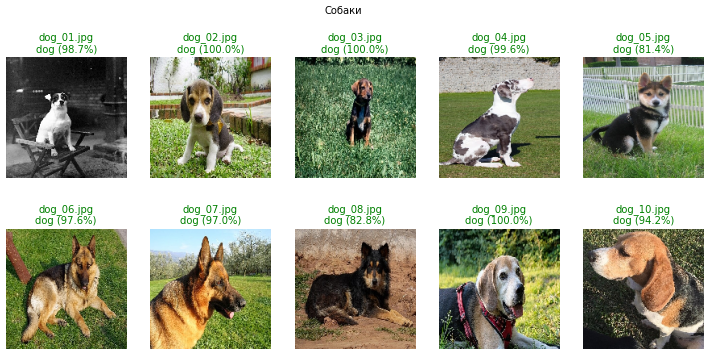

Правильно розпізнано: 10 з 10


In [25]:
recognize('cat_*.jpg', 'Коти')
recognize('dog_*.jpg', 'Собаки')

### Складні зображення

hard_cat_01.jpg: правильно - cat, мережа - dog (79.8%) ✗
hard_cat_02.jpg: правильно - cat, мережа - dog (96.2%) ✗
hard_cat_03.jpg: правильно - cat, мережа - dog (93.2%) ✗
hard_cat_04.jpg: правильно - cat, мережа - cat (53.1%) ✓
hard_cat_05.jpg: правильно - cat, мережа - dog (78.9%) ✗
hard_cat_06.jpg: правильно - cat, мережа - dog (97.4%) ✗
hard_cat_07.jpg: правильно - cat, мережа - cat (97.4%) ✓
hard_cat_08.jpg: правильно - cat, мережа - cat (95.0%) ✓
hard_cat_09.jpg: правильно - cat, мережа - dog (90.3%) ✗
hard_cat_10.jpg: правильно - cat, мережа - cat (66.1%) ✓
hard_dog_01.jpg: правильно - dog, мережа - dog (99.8%) ✓
hard_dog_02.jpg: правильно - dog, мережа - dog (95.7%) ✓
hard_dog_03.jpg: правильно - dog, мережа - dog (69.7%) ✓
hard_dog_04.jpg: правильно - dog, мережа - dog (96.9%) ✓
hard_dog_05.jpg: правильно - dog, мережа - dog (94.7%) ✓
hard_dog_06.jpg: правильно - dog, мережа - dog (99.0%) ✓
hard_dog_07.jpg: правильно - dog, мережа - dog (96.6%) ✓
hard_dog_08.jpg: правильно - do

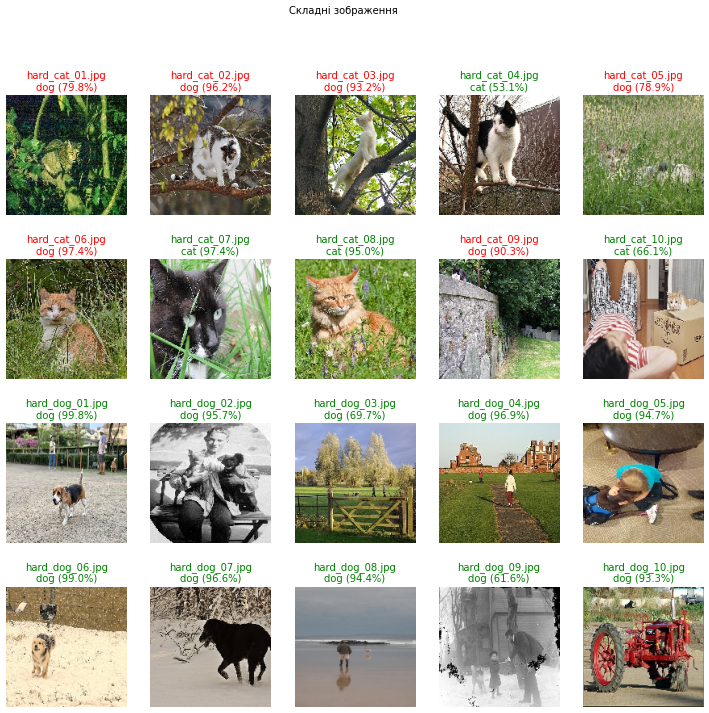

Правильно розпізнано: 14 з 20


In [26]:
recognize('hard_*.jpg', 'Складні зображення')

### Обрізані зображення

crop_cat_02.jpg: правильно - cat, мережа - cat (58.9%) ✓
crop_cat_03.jpg: правильно - cat, мережа - dog (77.6%) ✗
crop_cat_05.jpg: правильно - cat, мережа - dog (78.9%) ✗
crop_cat_06.jpg: правильно - cat, мережа - dog (93.1%) ✗
crop_cat_07.jpg: правильно - cat, мережа - cat (73.3%) ✓
crop_cat_08.jpg: правильно - cat, мережа - cat (98.0%) ✓
crop_dog_06.jpg: правильно - dog, мережа - dog (99.9%) ✓


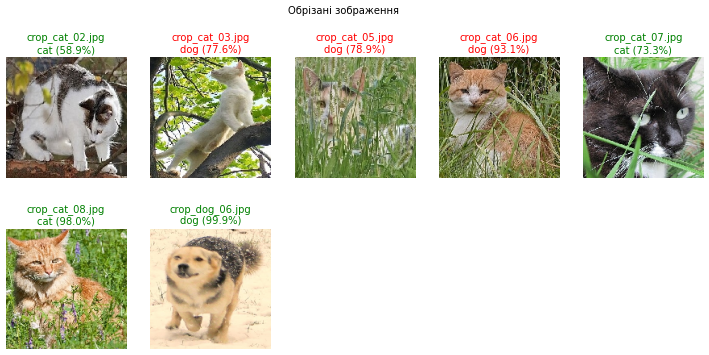

Правильно розпізнано: 4 з 7


In [27]:
recognize('crop_*.jpg', 'Обрізані зображення')